# Predicting Electric Motor Winding Temperature

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1T3DjZiorgPdzEpxWozfu8nXM11XAUzZ_?usp=sharing)

### UCS321 — AI for Engineers · MST Mini Project
**Problem Statement 6 — General Electric (GE) Power Systems**

> *GE Power Systems aims to improve the operational reliability of its electric motors by predicting
> winding temperatures under diverse working conditions. Using a dataset containing parameters such as
> ambient temperature, motor speed, load torque, supply voltage, and current, develop a supervised
> machine learning regression model to estimate motor temperature.*

---

## 1. Problem understanding and objective

A permanent-magnet synchronous motor (PMSM) fails when its stator winding insulation cooks. Class-H
insulation is rated to roughly **180 °C**; sustained operation past that limit degrades the varnish and
ends in a turn-to-turn short. So the winding temperature is the single quantity that bounds how hard a
drive is allowed to push the machine.

The engineering problem is that **you cannot cheaply measure it in a production motor.** Getting a
thermocouple onto a rotating, varnished, high-voltage winding means extra wiring through the housing,
an extra failure point, and a cost that does not survive contact with a volume BOM. Test benches have
these sensors. Shipped motors do not.

Every drive already measures, for free, the quantities it needs for field-oriented control:
phase currents, terminal voltages, rotor speed, and a coolant/ambient temperature. So:

> **Objective — estimate stator winding temperature from signals the drive already has, accurately
> enough that a controller can use it as a thermal limit instead of a thermocouple.**

This is a *virtual sensor* (or "soft sensor") problem. Getting it right means the drive can run closer
to the real thermal limit instead of derating conservatively, which is directly worth torque and power
density.

### What "accurate enough" means here

Average error is the wrong headline metric for a safety limit. A model with 1 °C mean error and a
20 °C worst-case spike will still destroy a motor. We therefore report, alongside the usual regression
metrics, **maximum absolute error** and **the fraction of samples within ±2 °C** — the numbers an
engineer would actually ask for.

---

### Running this in Google Colab

**Runtime > Run all** executes the whole notebook end to end. No GPU is needed — every model
here is CPU-bound, so leave the accelerator set to **None**.

| | |
|---|---|
| Expected wall-clock | **35–50 min** on a free CPU runtime |
| Of which Section 9 (hyperparameter search) | **~20–30 min** — set `FAST_MODE = True` below to cut it to ~5 min |
| Peak RAM | **≈ 6 GB** (104 features x 1.33 M rows, float32). The standard ~12.7 GB runtime is enough; a High-RAM runtime is not required |
| Disk | ≈ 300 MB for the dataset |

Colab recycles idle runtimes, so if you plan to walk away, run it in two sittings
(Sections 1–8, then 9 onward) rather than leaving it unattended for an hour.


## 2. Dataset

**Source:** *Electric Motor Temperature* (Paderborn University, LEA department) — test-bench telemetry
from a three-phase PMSM on a dynamometer. Downloaded from Kaggle as `measures_v2.csv`.

| Property | Value |
|---|---|
| Samples | 1,330,816 |
| Sampling rate | 2 Hz |
| Independent sessions (`profile_id`) | 69 |
| Total duration | ≈ 185 hours |
| Missing values | 0 |

**Channels**

| Column | Meaning | Role |
|---|---|---|
| `ambient` | ambient temperature (°C) | input |
| `coolant` | coolant outlet temperature (°C) | input |
| `u_d`, `u_q` | terminal voltage, dq frame (V) | input |
| `i_d`, `i_q` | phase current, dq frame (A) | input |
| `motor_speed` | rotor speed (rpm) | input |
| `torque` | shaft torque (Nm) | input |
| **`stator_winding`** | **winding temperature (°C)** | **TARGET** |
| `stator_tooth`, `stator_yoke`, `pm` | other thermocouple readings | *dropped — see §4* |

### Getting the dataset into Colab

The CSV is ~300 MB, so it is not in the repository. The next cell finds it whichever way you
bring it in and leaves the resolved location in `DATA_PATH`. It tries three routes in order and
stops at the first that works.

| Route | Set | What happens |
|---|---|---|
| **1 — already here** | nothing | Looks in `/content`, the current folder, and `data/raw/` |
| **2 — Google Drive** | `MOUNT_DRIVE = True` | Mounts your Drive and looks for `measures_v2.csv` in `MyDrive` (one folder deep). Best option if you will run this more than once — the file survives runtime restarts |
| **3 — Kaggle API** | `USE_KAGGLE = True` | Downloads [`wkirgsn/electric-motor-temperature`](https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature) directly. Needs a `kaggle.json` token (Kaggle > *Settings* > *API* > *Create New Token*); you will be prompted to upload it if it is not already present |

Manual upload also works if you prefer: use the folder icon in Colab's left sidebar to drop
`measures_v2.csv` into `/content`, then run the cell — route 1 will pick it up. Browser upload of
a 300 MB file is slow, so Drive or Kaggle is usually less painful.

In [ ]:
# ── dependencies ────────────────────────────────────────────────────────────
# Colab already ships numpy / pandas / scikit-learn / matplotlib. Only install
# what is actually missing, so the runtime does not get churned unnecessarily.
import importlib.util, subprocess, sys

for pkg in ["lightgbm", "pyarrow", "kaggle"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import sklearn, numpy, pandas
print(f"python       {sys.version.split()[0]}")
print(f"numpy        {numpy.__version__}")
print(f"pandas       {pandas.__version__}")
print(f"scikit-learn {sklearn.__version__}")
import lightgbm; print(f"lightgbm     {lightgbm.__version__}")

In [ ]:
# ── configuration ───────────────────────────────────────────────────────────
MOUNT_DRIVE = False   # True  -> mount Google Drive and look for the CSV there
USE_KAGGLE  = True    # True  -> fall back to the Kaggle API (needs kaggle.json)
FAST_MODE   = False   # True  -> shrink the Section 9 search from ~25 min to ~5 min

# ── locate measures_v2.csv ──────────────────────────────────────────────────
import glob, os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
KAGGLE_DATASET = "wkirgsn/electric-motor-temperature"

SEARCH = [
    "measures_v2.csv",
    "/content/measures_v2.csv",
    "/content/data/raw/measures_v2.csv",
    "../data/raw/measures_v2.csv",
    "/content/drive/MyDrive/measures_v2.csv",
    "/content/drive/MyDrive/*/measures_v2.csv",
]

def locate():
    """First matching location wins; within a location, the largest file wins -
    a failed download can leave a stub next to the real thing."""
    for pattern in SEARCH:
        hits = [h for h in glob.glob(pattern) if os.path.isfile(h)]
        if hits:
            return max(hits, key=os.path.getsize)
    return None

DATA_PATH = locate()

# Route 2 — Google Drive
if DATA_PATH is None and IN_COLAB and MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = locate()

# Route 3 — Kaggle API
if DATA_PATH is None and IN_COLAB and USE_KAGGLE:
    token = Path.home() / ".kaggle" / "kaggle.json"
    if not token.exists():
        local = sorted(glob.glob("/content/kaggle.json")) + sorted(glob.glob("kaggle.json"))
        if not local:
            print("Upload kaggle.json  (Kaggle > Settings > API > Create New Token)")
            from google.colab import files
            files.upload()
            local = sorted(glob.glob("kaggle.json")) + sorted(glob.glob("/content/kaggle.json"))
        if local:
            token.parent.mkdir(parents=True, exist_ok=True)
            token.write_bytes(Path(local[0]).read_bytes())
            token.chmod(0o600)
    if token.exists():
        import kaggle                      # authenticates on import
        print(f"downloading {KAGGLE_DATASET} ...")
        kaggle.api.dataset_download_files(KAGGLE_DATASET, path="/content", unzip=True)
        DATA_PATH = locate()

if DATA_PATH is None:
    raise FileNotFoundError(
        "measures_v2.csv not found.\n"
        "  - put it in /content (sidebar folder icon > upload), or\n"
        "  - set MOUNT_DRIVE = True if it is in your Google Drive, or\n"
        "  - set USE_KAGGLE = True and upload a kaggle.json token,\n"
        f"then re-run this cell. Searched: {SEARCH}"
    )

_bytes = os.path.getsize(DATA_PATH)
if _bytes < 200_000_000:
    raise ValueError(
        f"{DATA_PATH} is only {_bytes/1e6:.1f} MB; the real measures_v2.csv is about 300 MB.\\n"
        "That is a stub, a truncated upload, or a failed download rather than the "
        "dataset. Delete it and fetch it again:\\n"
        "  !rm -f /content/measures_v2.csv\\n"
        "then re-run this cell."
    )

print(f"dataset   : {DATA_PATH}")
print(f"size      : {_bytes/1e6:.0f} MB")
print(f"FAST_MODE : {FAST_MODE}")

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone
import joblib

FS   = 2.0     # sampling rate, Hz
RNG  = 42
PATH = DATA_PATH   # resolved by the setup cell above

df = pd.read_csv(PATH)

# --- sanity gate: fail here, loudly, rather than 12 cells later inside sklearn ---
EXPECTED_COLS = {"ambient", "coolant", "u_d", "u_q", "i_d", "i_q", "motor_speed",
                 "torque", "stator_winding", "stator_tooth", "stator_yoke", "pm",
                 "profile_id"}
_processed = [c for c in df.columns if "_ewma_" in c or "_ewms_" in c]
if _processed:
    raise ValueError(
        f"The file at {PATH} already contains {len(_processed)} engineered feature "
        "columns, so it is a processed intermediate produced by this pipeline, not "
        "the raw dataset.\n"
        "The real measures_v2.csv has exactly 13 columns and 1,330,816 rows. Delete "
        "this file and download the real one:\n"
        "  https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature"
    )

_missing = EXPECTED_COLS - set(df.columns)
if len(df) == 0 or _missing:
    raise ValueError(
        f"The file at {PATH} is not the expected dataset.\n"
        f"  rows read       : {len(df):,}   (expected 1,330,816)\n"
        f"  columns found   : {sorted(df.columns)}\n"
        f"  columns missing : {sorted(_missing) if _missing else 'none'}\n"
        "Re-download measures_v2.csv - a 0-row or truncated file is usually an "
        "interrupted upload or a failed Kaggle download that left a stub behind."
    )

for c in df.columns:
    if c != "profile_id":
        df[c] = df[c].astype("float32")

print(f"{len(df):,} samples x {df.shape[1]} channels")
print(f"{df.profile_id.nunique()} sessions, {len(df)/FS/3600:.1f} hours")
print(f"missing values: {df.isna().sum().sum()}")
df.head()

1,330,816 samples x 13 channels
69 sessions, 184.8 hours
missing values: 0


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [2]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
u_q,1330816.0,54.28,44.17,-25.29,12.07,48.94,90.03,133.04
coolant,1330816.0,36.23,21.79,10.62,18.70,26.90,49.86,101.60
stator_winding,1330816.0,66.34,28.67,18.59,42.79,65.11,88.14,141.36
u_d,1330816.0,-25.13,63.09,-131.53,-78.69,-7.43,1.47,131.47
stator_tooth,1330816.0,56.88,22.95,18.13,38.42,56.04,75.59,111.95
motor_speed,1330816.0,2202.08,1859.66,-275.55,317.11,1999.98,3760.64,6000.02
i_d,1330816.0,-68.72,64.93,-278.00,-115.41,-51.09,-2.98,0.05
i_q,1330816.0,37.41,92.18,-293.43,1.10,15.77,100.61,301.71
pm,1330816.0,58.51,19.00,20.86,43.15,60.27,72.01,113.61
stator_yoke,1330816.0,48.19,19.99,18.08,31.99,45.63,61.46,101.15


## 3. Exploratory data analysis

### 3.1 The dominant physical fact: thermal inertia

Plot the electrical excitation and the thermal response of one session on the same time axis.

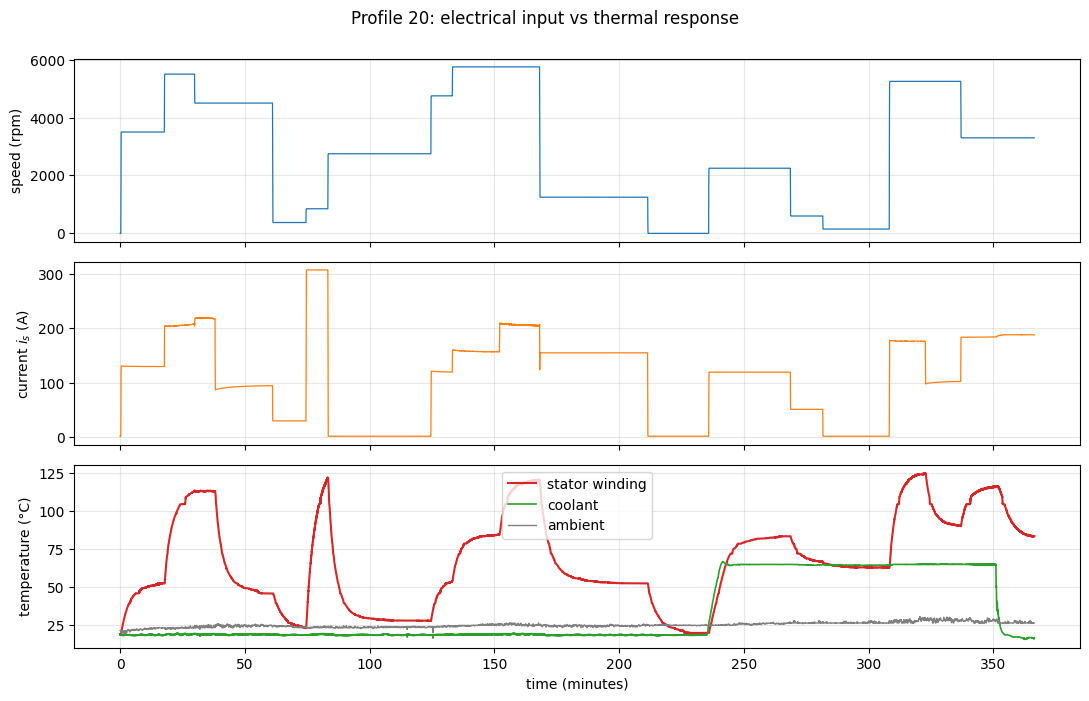

In [3]:
pid = df.groupby("profile_id").size().idxmax()      # longest session
d   = df[df.profile_id == pid].reset_index(drop=True)
t   = np.arange(len(d)) / FS / 60                   # minutes

fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ax[0].plot(t, d.motor_speed, lw=0.9);  ax[0].set_ylabel("speed (rpm)")
ax[1].plot(t, np.sqrt(d.i_d**2 + d.i_q**2), lw=0.9, color="tab:orange")
ax[1].set_ylabel("current $i_s$ (A)")
ax[2].plot(t, d.stator_winding, lw=1.5, color="tab:red", label="stator winding")
ax[2].plot(t, d.coolant, lw=1.2, color="tab:green", label="coolant")
ax[2].plot(t, d.ambient, lw=1.0, color="gray", label="ambient")
ax[2].set_ylabel("temperature (°C)"); ax[2].set_xlabel("time (minutes)"); ax[2].legend()
for a in ax: a.grid(alpha=.3)
fig.suptitle(f"Profile {pid}: electrical input vs thermal response", y=.995)
plt.tight_layout(); plt.show()

Read the bottom panel against the middle one. The current changes in **seconds**; the winding
temperature takes **minutes** to respond, and keeps rising after the current has already stepped down.

This is the whole problem in one picture. The winding temperature is not a function of the present
current — it is a function of the *accumulated* loss over the recent past. A model fed only
instantaneous values is being asked to infer a state variable from its derivative, which it cannot do.

### 3.2 Correlation of raw signals with the target

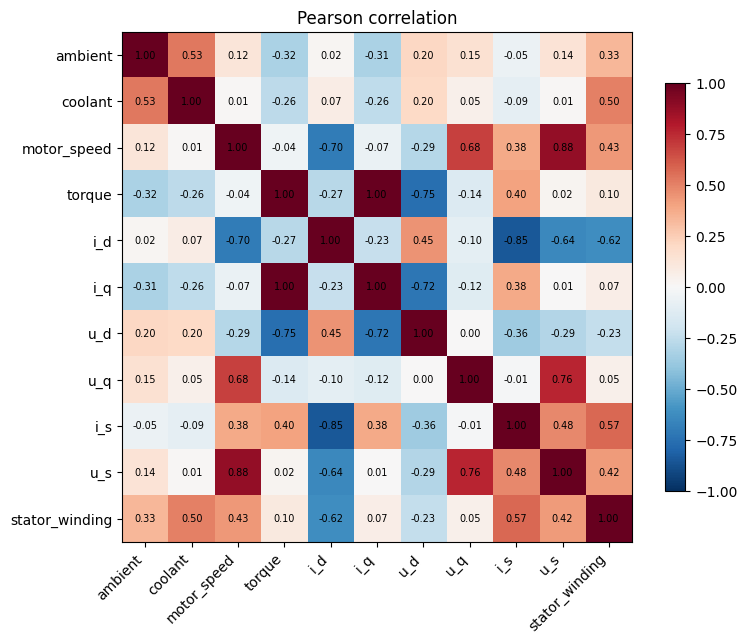

i_d            0.624
i_s            0.572
coolant        0.505
motor_speed    0.432
u_s            0.423
ambient        0.333
u_d            0.235
torque         0.096
i_q            0.066
u_q            0.051
Name: stator_winding, dtype: float64


In [4]:
df["i_s"]  = np.sqrt(df.i_d**2 + df.i_q**2)
df["u_s"]  = np.sqrt(df.u_d**2 + df.u_q**2)

cols = ["ambient","coolant","motor_speed","torque","i_d","i_q","u_d","u_q","i_s","u_s","stator_winding"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=.8); ax.set_title("Pearson correlation"); plt.tight_layout(); plt.show()

print(corr["stator_winding"].drop("stator_winding").abs().sort_values(ascending=False).round(3))

No raw electrical channel reaches |r| = 0.63 against the target. That ceiling is not a data-quality
problem — it is the thermal inertia from §3.1 showing up numerically. Feature engineering, not model
choice, is what will break it.

## 4. Pre-processing

### 4.1 Dropping the leaking channels — the most important decision in this project

The dataset contains three other thermocouple readings: `stator_tooth`, `stator_yoke`, and `pm`
(permanent magnet). They correlate with `stator_winding` at r > 0.95, so including them produces a
spectacular R².

**We drop all three.** Two reasons, and both matter:

1. **It defeats the purpose.** Those sensors are exactly the hardware we are trying to remove. A model
   that needs `stator_tooth` to predict `stator_winding` cannot be deployed on a motor that has neither.
2. **It is target leakage.** The tooth and yoke sit millimetres from the winding in the same iron. A
   model using them is interpolating between adjacent thermocouples, not learning motor thermodynamics.

`coolant` and `ambient` are **kept** — those are cheap, standard, and present on any real drive.

This leaves 8 input channels, all of which a production motor controller already measures.

In [5]:
LEAKY  = ["stator_tooth", "stator_yoke", "pm"]
TARGET = "stator_winding"
BASE   = ["ambient", "coolant", "u_d", "u_q", "motor_speed", "i_d", "i_q", "torque"]

print("correlation of the dropped channels with the target:")
print(df[LEAKY + [TARGET]].corr()[TARGET].drop(TARGET).round(4))

df = df.drop(columns=LEAKY)
print(f"\nretained inputs ({len(BASE)}): {BASE}")

correlation of the dropped channels with the target:
stator_tooth    0.9701
stator_yoke     0.8603
pm              0.7959
Name: stator_winding, dtype: float64

retained inputs (8): ['ambient', 'coolant', 'u_d', 'u_q', 'motor_speed', 'i_d', 'i_q', 'torque']


### 4.2 Quality checks

The dataset ships clean (no missing values, no duplicated timestamps), so preprocessing is about
*structure* rather than repair: we verify that each `profile_id` is one contiguous recording session,
because every feature built in §5 depends on that assumption.

missing values per column:
0 total



duplicate rows: 0


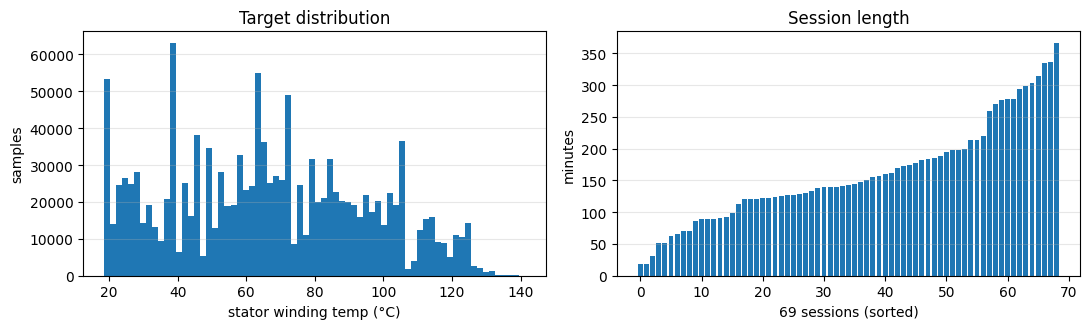

target range: 18.6 – 141.4 °C
session length: 18 – 366 min


In [6]:
print("missing values per column:"); print(df.isna().sum().sum(), "total")
print("\nduplicate rows:", df.duplicated().sum())

sess = (df.groupby("profile_id").size() / FS / 60).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df[TARGET], bins=70); ax[0].set_xlabel("stator winding temp (°C)")
ax[0].set_ylabel("samples"); ax[0].set_title("Target distribution")
ax[1].bar(range(len(sess)), sess.values); ax[1].set_xlabel(f"{len(sess)} sessions (sorted)")
ax[1].set_ylabel("minutes"); ax[1].set_title("Session length")
for a in ax: a.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

print(f"target range: {df[TARGET].min():.1f} – {df[TARGET].max():.1f} °C")
print(f"session length: {sess.min():.0f} – {sess.max():.0f} min")

### 4.3 A systematic data-quality audit

Checking for missing values is the minimum. Below is the full audit that was actually run, including
physical-plausibility checks — because on sensor data the dangerous defects are the ones that are
numerically valid and physically impossible.

In [7]:
print("=== completeness ===")
print(f"  NaN cells              : {int(df.isna().sum().sum())}")
print(f"  infinite cells         : {int(np.isinf(df.select_dtypes('number')).sum().sum())}")
print(f"  duplicate rows         : {int(df.duplicated().sum())}")
nun = df.nunique()
print(f"  constant columns       : {list(nun[nun <= 1].index) or 'none'}")

print("\n=== session structure ===")
noncontig = [pid for pid, idx in df.groupby('profile_id').indices.items()
             if idx.max() - idx.min() + 1 != len(idx)]
print(f"  sessions not contiguous in file order: {noncontig or 'none'}")
print("  -> contiguous sessions are what make the per-profile EWMA in 5.2 safe")

print("\n=== physical plausibility ===")
i_s_raw = np.sqrt(df.i_d**2 + df.i_q**2)
for label, n in [
    ("winding below ambient",      int((df[TARGET] < df.ambient - 1).sum())),
    ("winding above 200 C",        int((df[TARGET] > 200).sum())),
    ("|speed| above 6500 rpm",     int((df.motor_speed.abs() > 6500).sum())),
    ("current above 400 A",        int((i_s_raw > 400).sum())),
    ("ambient outside 0-50 C",     int(((df.ambient < 0) | (df.ambient > 50)).sum())),
]:
    print(f"  {'OK ' if n == 0 else '?? '}{label:<26} {n:>7,}")

=== completeness ===
  NaN cells              : 0
  infinite cells         : 0


  duplicate rows         : 0


  constant columns       : none

=== session structure ===
  sessions not contiguous in file order: none
  -> contiguous sessions are what make the per-profile EWMA in 5.2 safe

=== physical plausibility ===
  ?? winding below ambient       69,386
  OK winding above 200 C              0
  OK |speed| above 6500 rpm           0
  OK current above 400 A              0
  OK ambient outside 0-50 C           0


One check fires: **69,386 rows (5.2 %) where the winding sits below ambient.** That looks
thermodynamically impossible, so it was investigated rather than ignored.

In [8]:
m = df[TARGET] < df.ambient - 1
sub = df[m]
print(f"rows flagged                        : {int(m.sum()):,}  ({m.mean()*100:.1f} %)")
print(f"  of those, coolant also below ambient: {(sub.coolant < sub.ambient).mean()*100:.1f} %")
print(f"  median coolant   : {sub.coolant.median():.1f} C")
print(f"  median ambient   : {sub.ambient.median():.1f} C")
print(f"  median current   : {np.sqrt(sub.i_d**2 + sub.i_q**2).median():.1f} A"
      f"   (vs {np.sqrt(df.i_d**2 + df.i_q**2).median():.1f} A overall)")

rows flagged                        : 69,386  (5.2 %)
  of those, coolant also below ambient: 99.9 %
  median coolant   : 18.5 C
  median ambient   : 23.0 C
  median current   : 2.3 A   (vs 110.6 A overall)


Explained: a liquid-cooled motor sitting near-idle with **chilled coolant** running through it. The
machine is being actively refrigerated below room temperature. Entirely physical — no correction needed.

Two smaller flags were chased the same way and also came back clean: nine negative-speed samples turn
out to be one genuine four-second direction reversal in session 51, and the 85 samples where
temperature moves more than 1 °C in half a second all sit at 106–109 °C under ~194 A, which is real
fast heating under heavy load.

**Conclusion: the dataset needs no repair.** That is worth establishing explicitly rather than assuming.

## 5. Feature engineering

This is where the project is won. Two families of features.

### 5.1 Physically-motivated derived quantities

The dq-frame components are control-convenient but not thermally meaningful on their own. What heats a
winding is **copper loss**, $P_{cu} = 3 I^2 R$ — so the model should be handed $i_s$ and especially
$i_s^2$ rather than being asked to discover the square law from $i_d$ and $i_q$.

$$i_s=\sqrt{i_d^2+i_q^2} \qquad u_s=\sqrt{u_d^2+u_q^2} \qquad S_{el}=\tfrac{3}{2}\,i_s u_s$$
$$P_{mech}=\frac{2\pi}{60}\,\tau\,n \qquad P_{loss}\approx S_{el}-|P_{mech}|$$

### 5.2 Exponentially weighted moving averages — the thermal memory

A lumped-parameter thermal model of a motor is a first-order system:

$$C_{th}\frac{d\vartheta}{dt} = P_{loss}(t) - \frac{\vartheta - \vartheta_{amb}}{R_{th}}
\qquad\Longrightarrow\qquad
\vartheta(t)=\frac{1}{\tau}\int_{-\infty}^{t} e^{-(t-s)/\tau} P_{loss}(s)\,ds$$

That integral — an exponentially weighted average of past losses — **is** an EWMA. So computing EWMAs
of the loss-related signals does not just "smooth the data": it hands the model the exact functional
form the physics produces. This is what makes even a linear model work in §7.

Because a motor has several thermal masses with different time constants (winding ≈ tens of seconds,
iron ≈ minutes, housing and coolant ≈ tens of minutes), we compute EWMAs at **five spans** — 30 s,
120 s, 600 s, 1800 s, 3600 s — and let the model pick. We add the exponentially weighted **standard
deviation** at each span too, which encodes how volatile the recent duty cycle has been.

> **Critical implementation detail:** every EWMA is computed **within a `profile_id` group**. Sessions
> are separate experiments — letting the filter run across a boundary would import the thermal state of
> an unrelated recording, which is leakage.

In [9]:
def add_physical(d):
    d = d.copy()
    d["i_s"]    = np.sqrt(d.i_d**2 + d.i_q**2)
    d["u_s"]    = np.sqrt(d.u_d**2 + d.u_q**2)
    d["S_el"]   = 1.5 * d.i_s * d.u_s              # apparent electrical power
    d["i_s_sq"] = d.i_s**2                          # copper-loss proxy (I^2 R)
    d["P_mech"] = d.torque * d.motor_speed * 2*np.pi/60
    d["P_loss"] = d.S_el - d.P_mech.abs()
    return d

EWM_COLS  = ["i_s","u_s","S_el","i_s_sq","P_loss","motor_speed","torque","coolant","ambient"]
EWM_SPANS = [30, 120, 600, 1800, 3600]             # seconds

def add_ewm(d, spans=EWM_SPANS):
    g, new = d.groupby("profile_id", sort=False), {}
    for s in spans:
        sp = int(s * FS)
        for c in EWM_COLS:
            new[f"{c}_ewma_{s}s"] = g[c].transform(lambda x, k=sp: x.ewm(span=k, adjust=False).mean()).astype("float32")
            new[f"{c}_ewms_{s}s"] = g[c].transform(lambda x, k=sp: x.ewm(span=k, adjust=False).std()).astype("float32")
    return pd.concat([d, pd.DataFrame(new, index=d.index)], axis=1).fillna(0.0)

df = add_ewm(add_physical(df))
FEATS = [c for c in df.columns if c not in (TARGET, "profile_id")]
print(f"{len(BASE)} raw channels -> {len(FEATS)} features")

8 raw channels -> 104 features


### 5.3 Does it actually help? A single-feature check

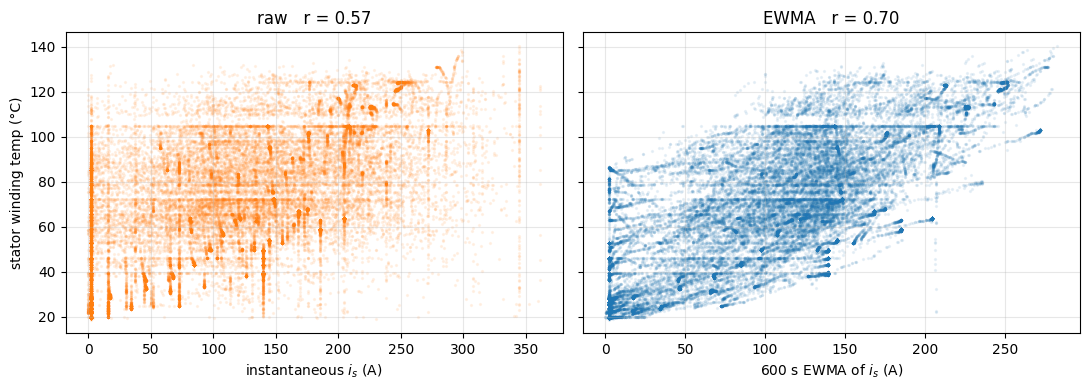

In [10]:
r_raw  = np.corrcoef(df.i_s,               df[TARGET])[0,1]
r_ewma = np.corrcoef(df["i_s_ewma_600s"],  df[TARGET])[0,1]

s = df.sample(40000, random_state=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].scatter(s.i_s,              s[TARGET], s=2, alpha=.08, color="tab:orange")
ax[0].set_xlabel("instantaneous $i_s$ (A)"); ax[0].set_title(f"raw   r = {r_raw:.2f}")
ax[1].scatter(s["i_s_ewma_600s"], s[TARGET], s=2, alpha=.08)
ax[1].set_xlabel("600 s EWMA of $i_s$ (A)"); ax[1].set_title(f"EWMA   r = {r_ewma:.2f}")
ax[0].set_ylabel("stator winding temp (°C)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Train / test split — why random splitting is wrong here

The obvious move is `train_test_split(X, y, test_size=0.2)`. **On this dataset that produces a
meaningless result**, and it is worth being explicit about why.

Samples are 0.5 s apart. Consecutive rows are near-identical: a motor's temperature cannot change
appreciably in half a second. A random split therefore scatters near-duplicate rows across train and
test, so the test set is effectively *already in* the training set. The model gets rewarded for
memorising, and reports an R² of ~0.9995.

The honest protocol is to hold out **entire measurement sessions**. The model is then evaluated the way
it would actually be used: on a motor run it has never seen. We use profiles **65 and 72** as the test
set (the benchmark sessions used in the published literature on this bench) and three further profiles
for validation.

We quantify the difference in §9.

In [11]:
TEST_P, VAL_P = [65, 72], [60, 62, 74]

te, va = df.profile_id.isin(TEST_P), df.profile_id.isin(VAL_P)
tr     = ~(te | va)

# --- sanity gate: an empty split is the failure mode that is hardest to read ---
_have, _want = set(df.profile_id.unique()), set(TEST_P) | set(VAL_P)
if not _want <= _have:
    raise ValueError(
        f"Profiles {sorted(_want - _have)} are not in this dataset.\n"
        f"  profiles present ({len(_have)}): {sorted(_have)}\n"
        "The reported results are defined on profiles 65 and 72, so a dataset "
        "without them is the wrong file, not a reason to pick other profiles."
    )
for _n, _m in [("train", tr), ("val", va), ("test", te)]:
    if _m.sum() == 0:
        raise ValueError(
            f"The {_n} split is empty ({len(df):,} rows loaded, "
            f"{df.profile_id.nunique()} profiles). Check the cell above this one."
        )

Xtr, ytr = df.loc[tr, FEATS], df.loc[tr, TARGET]
Xva, yva = df.loc[va, FEATS], df.loc[va, TARGET]
Xte, yte = df.loc[te, FEATS], df.loc[te, TARGET]

print(f"train  {tr.sum():>9,}  ({df.loc[tr,'profile_id'].nunique()} profiles)")
print(f"val    {va.sum():>9,}  ({len(VAL_P)} profiles)")
print(f"test   {te.sum():>9,}  (profiles {TEST_P})")

# 2 Hz data is heavily autocorrelated; every 10th sample loses ~nothing and
# keeps the slower learners tractable.
Xtr_s, ytr_s = Xtr.iloc[::10], ytr.iloc[::10]
print(f"\nsubsampled train set for RF / MLP: {len(Xtr_s):,}")

train  1,211,517  (64 profiles)
val       63,904  (3 profiles)
test      55,395  (profiles [65, 72])

subsampled train set for RF / MLP: 121,152


## 7. Model development

A ladder from the simplest thing that could work to the most flexible, so that every increment in
complexity has to justify itself.

| Model | Purpose |
|---|---|
| Linear regression, raw inputs | the honest floor — what you get with no feature engineering |
| Ridge regression, engineered features | isolates the value of §5 |
| Random Forest | non-linear, non-parametric reference |
| MLP (2 × 128) | smooth function approximator, suits a continuous physical system |
| LightGBM | strong tabular baseline, early-stopped on the validation profiles |

In [12]:
def scores(y, p):
    e = np.abs(y - p)
    return dict(RMSE=float(np.sqrt(mean_squared_error(y, p))),
                MAE=float(mean_absolute_error(y, p)),
                R2=float(r2_score(y, p)),
                MaxAE=float(e.max()),
                within_2C=float((e <= 2).mean()*100))

results, preds = {}, {}

def run(name, model, cols=None, X=None, y=None):
    cols = cols or FEATS
    X = Xtr if X is None else X
    y = ytr if y is None else y
    model.fit(X[cols], y)
    p = model.predict(Xte[cols])
    results[name], preds[name] = scores(yte.values, p), p
    r = results[name]
    print(f"{name:<30} RMSE {r['RMSE']:6.3f}  MAE {r['MAE']:6.3f}  R2 {r['R2']:7.4f}  "
          f"MaxAE {r['MaxAE']:6.2f}  ±2°C {r['within_2C']:5.1f}%")
    return model

In [13]:
run("Linear (raw inputs only)", make_pipeline(StandardScaler(), LinearRegression()), cols=BASE)
run("Linear (+ EWMA features)", make_pipeline(StandardScaler(), Ridge(alpha=1.0)))

Linear (raw inputs only)       RMSE 17.794  MAE 14.368  R2  0.5324  MaxAE  69.27  ±2°C   8.1%


Linear (+ EWMA features)       RMSE  2.079  MAE  1.537  R2  0.9936  MaxAE  26.19  ±2°C  71.7%


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None


Pause on those two lines. **Same algorithm. Same data. RMSE falls from ~17.8 °C to ~2.1 °C, R² from
0.53 to 0.99.** Nothing changed but the features. This is the central result of the project and it
argues something worth saying out loud in the report: *domain-informed feature engineering outperforms
model sophistication.*

In [14]:
run("Random Forest (80 trees)",
    RandomForestRegressor(n_estimators=80, max_depth=16, min_samples_leaf=20,
                          max_features=0.35, n_jobs=-1, random_state=RNG),
    X=Xtr_s, y=ytr_s)

run("MLP (2 x 128)",
    make_pipeline(StandardScaler(),
                  MLPRegressor(hidden_layer_sizes=(128,128), max_iter=60,
                               early_stopping=True, n_iter_no_change=6, random_state=RNG)),
    X=Xtr_s, y=ytr_s)

Random Forest (80 trees)       RMSE  3.604  MAE  2.487  R2  0.9808  MaxAE  15.56  ±2°C  56.8%


MLP (2 x 128)                  RMSE  1.666  MAE  1.265  R2  0.9959  MaxAE   9.84  ±2°C  81.3%


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('mlpregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_ne

In [15]:
import lightgbm as lgb
gbm = lgb.LGBMRegressor(n_estimators=900, learning_rate=0.06, num_leaves=96,
                        min_child_samples=60, subsample=0.8, subsample_freq=1,
                        colsample_bytree=0.8, random_state=RNG, n_jobs=-1, verbose=-1)
gbm.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(60, verbose=False)])
p = gbm.predict(Xte)
results["LightGBM"], preds["LightGBM"] = scores(yte.values, p), p
r = results["LightGBM"]
print(f"{'LightGBM':<30} RMSE {r['RMSE']:6.3f}  MAE {r['MAE']:6.3f}  R2 {r['R2']:7.4f}  "
      f"MaxAE {r['MaxAE']:6.2f}  ±2°C {r['within_2C']:5.1f}%   ({gbm.best_iteration_} trees)")

LightGBM                       RMSE  2.501  MAE  1.846  R2  0.9908  MaxAE  11.05  ±2°C  65.8%   (743 trees)


## 8. Performance evaluation and interpretation

These are the *untuned* ladder results — the point of the ladder is the comparison, not the final
number. Section 9 tunes the two strongest families and reports the final selected model.

In [16]:
tbl = pd.DataFrame(results).T[["RMSE","MAE","R2","MaxAE","within_2C"]].round(3)
tbl.columns = ["RMSE (°C)","MAE (°C)","R²","Max abs err (°C)","Within ±2 °C (%)"]
tbl.sort_values("RMSE (°C)")

,RMSE (°C),MAE (°C),R²,Max abs err (°C),Within ±2 °C (%)
MLP (2 x 128),1.666,1.265,0.996,9.838,81.318
Linear (+ EWMA features),2.079,1.537,0.994,26.193,71.734
LightGBM,2.501,1.846,0.991,11.046,65.789
Random Forest (80 trees),3.604,2.487,0.981,15.562,56.807
Linear (raw inputs only),17.794,14.368,0.532,69.269,8.105


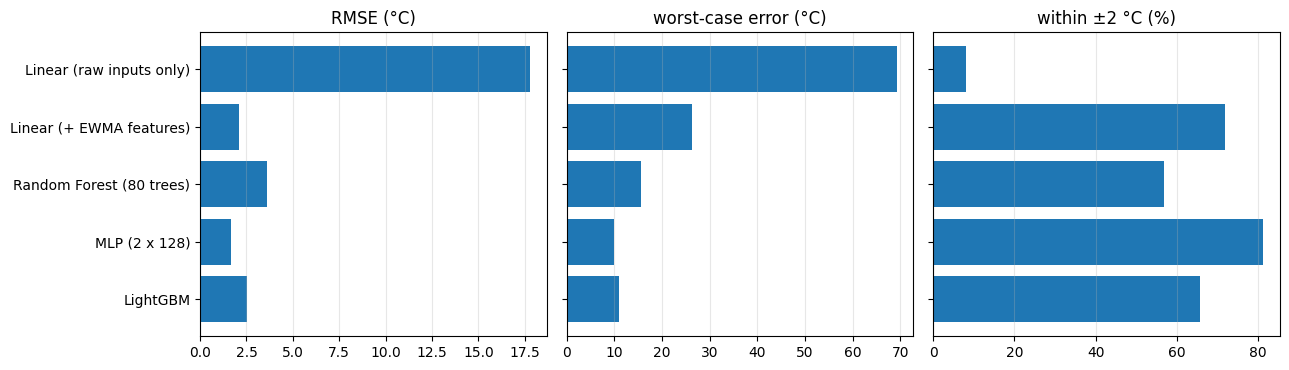

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
names = list(results)
for a, k, lab in [(ax[0],"RMSE","RMSE (°C)"), (ax[1],"MaxAE","worst-case error (°C)"),
                  (ax[2],"within_2C","within ±2 °C (%)")]:
    v = [results[n][k] for n in names]
    a.barh(range(len(names))[::-1], v)
    a.set_yticks(range(len(names))[::-1]); a.set_yticklabels(names if a is ax[0] else [])
    a.set_title(lab); a.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

best model: MLP (2 x 128)


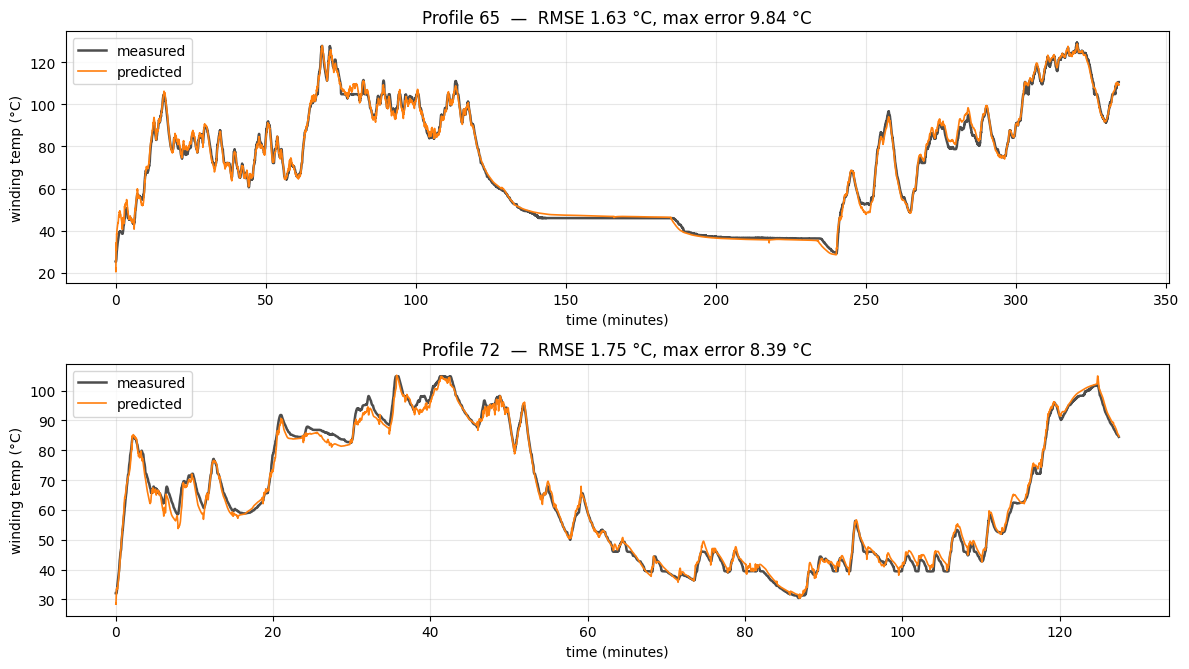

In [18]:
best = min(results, key=lambda k: results[k]["RMSE"])
pb   = preds[best]
pid_te = df.loc[te, "profile_id"].values
print("best model:", best)

fig, ax = plt.subplots(len(TEST_P), 1, figsize=(12, 3.4*len(TEST_P)))
for a, q in zip(np.atleast_1d(ax), TEST_P):
    m = pid_te == q
    t = np.arange(m.sum())/FS/60
    a.plot(t, yte.values[m], lw=1.8, color="0.3", label="measured")
    a.plot(t, pb[m],         lw=1.2, color="tab:orange", label="predicted")
    e = np.abs(yte.values[m] - pb[m])
    a.set_title(f"Profile {q}  —  RMSE {np.sqrt((e**2).mean()):.2f} °C, max error {e.max():.2f} °C")
    a.set_xlabel("time (minutes)"); a.set_ylabel("winding temp (°C)")
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

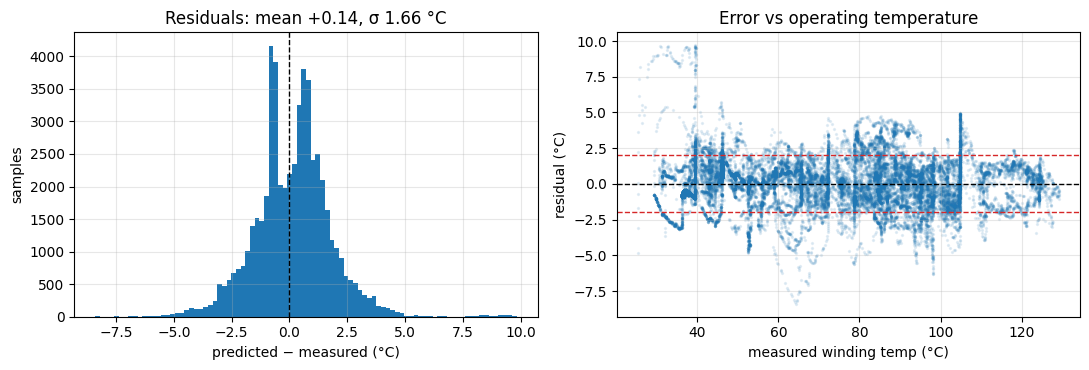

In [19]:
err = pb - yte.values
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(err, bins=90); ax[0].axvline(0, color="k", ls="--", lw=1)
ax[0].set_xlabel("predicted − measured (°C)"); ax[0].set_ylabel("samples")
ax[0].set_title(f"Residuals: mean {err.mean():+.2f}, σ {err.std():.2f} °C")
i = np.random.RandomState(0).choice(len(yte), 30000, replace=False)
ax[1].scatter(yte.values[i], err[i], s=2, alpha=.1)
for s_ in (0, 2, -2): ax[1].axhline(s_, color="k" if s_==0 else "tab:red", ls="--", lw=1)
ax[1].set_xlabel("measured winding temp (°C)"); ax[1].set_ylabel("residual (°C)")
ax[1].set_title("Error vs operating temperature")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Interpreting the comparison

Three things in that table are worth commenting on rather than just reporting:

1. **The MLP wins, and the gradient-boosted trees lose to a linear model.** That is not a bug. Tree
   ensembles are piecewise-constant: they cannot extrapolate outside the range of the training data.
   The held-out sessions contain operating points the training profiles never visit, and a tree
   ensemble can only clamp to the nearest leaf it saw. A neural network — a smooth function — continues
   the trend. For a continuous physical system evaluated on genuinely unseen conditions, smoothness is
   the property that matters.

2. **Ridge regression beats LightGBM.** Once the features encode the physics, the residual relationship
   is close to linear, and a low-variance model generalises better across sessions than a
   high-capacity one.

3. **Max error and RMSE do not rank models identically.** Note that the linear model's worst-case error
   is far larger than its RMSE suggests. For a thermal protection function, that column is the one that
   decides deployability.

## 9. Hyperparameter tuning

The ladder used fixed, sensible configurations. The two strongest families are now tuned properly —
with one constraint that matters more than the search itself.

> **Grouped cross-validation is not optional here.**
>
> The search uses `GroupKFold` with `profile_id` as the grouping key, so a candidate configuration is
> **never scored on a session it was fitted on**. A plain `KFold` inside the search would reintroduce
> exactly the leakage §6 removes from the outer split — and it would do so *invisibly*, because the
> reported CV score would simply look better.

Each search runs on every tenth training sample; the winning configuration is then refitted on the
full training partition. **This cell takes roughly 20 minutes.**

> **This is the slow cell — budget 20–30 minutes on a free Colab CPU runtime.**
>
> It fits 18 candidate models, each across 3 grouped folds, then refits the two winners on the
> full training set. If you only want to see the mechanics work, set `FAST_MODE = True` in the
> setup cell at the top and re-run from there: that thins the search set 4x and drops to 7
> candidates, finishing in about 5 minutes.
>
> `FAST_MODE` changes only the *search*, never the train/test split or the final evaluation — but
> the reported best hyperparameters and the final metrics will differ from the numbers discussed
> in the text below, which come from the full search. Leave it `False` to reproduce the report.

In [20]:
cv  = GroupKFold(n_splits=3)
STRIDE = 40 if FAST_MODE else 10                 # FAST_MODE thins the search set 4x
sub = df.loc[~te].iloc[::STRIDE]                 # train + val, never the test profiles
Xs, ys, gs = sub[FEATS], sub[TARGET], sub['profile_id']
print(f"search set: {len(sub):,} samples across {gs.nunique()} profiles")
print(f"test set:   {int(te.sum()):,} samples (profiles {TEST_P}) — untouched\n")

SPACES = {
    "MLP": (
        Pipeline([("scale", StandardScaler()),
                  ("model", MLPRegressor(early_stopping=True, n_iter_no_change=6,
                                         max_iter=80, random_state=RNG))]),
        {"model__hidden_layer_sizes": [(64,64), (128,128), (256,128), (128,128,64)],
         "model__alpha": [1e-5, 1e-4, 1e-3, 1e-2],
         "model__learning_rate_init": [5e-4, 1e-3, 3e-3]}, 3 if FAST_MODE else 8),
    "HistGradientBoosting": (
        HistGradientBoostingRegressor(early_stopping=True, n_iter_no_change=20,
                                      random_state=RNG),
        {"max_iter": [300, 500, 800], "learning_rate": [0.03, 0.06, 0.1],
         "max_leaf_nodes": [31, 63, 127], "min_samples_leaf": [20, 50, 100],
         "l2_regularization": [0.0, 0.1, 1.0]}, 4 if FAST_MODE else 10),
}

tuned, tuning = {}, {}
for name, (est, space, n_iter) in SPACES.items():
    print(f"--- tuning {name} ({n_iter} candidates x 3 grouped folds) ---")
    rs = RandomizedSearchCV(est, space, n_iter=n_iter, cv=cv,
                            scoring="neg_root_mean_squared_error",
                            random_state=RNG, n_jobs=1, refit=True)
    rs.fit(Xs, ys, groups=gs)
    print(f"    best CV RMSE {-rs.best_score_:.3f} °C")
    print(f"    params: {rs.best_params_}")
    final = clone(rs.best_estimator_)          # clone handles Pipelines correctly
    final.fit(Xtr, ytr)
    s_ = scores(yte.values, final.predict(Xte))
    results[f"{name} (tuned)"] = s_
    preds[f"{name} (tuned)"]   = final.predict(Xte)
    tuned[name], tuning[name] = final, {"cv_rmse": float(-rs.best_score_), "test": s_}
    print(f"    test: RMSE {s_['RMSE']:.3f}  MAE {s_['MAE']:.3f}  R2 {s_['R2']:.4f}  "
          f"MaxAE {s_['MaxAE']:.2f}  ±2°C {s_['within_2C']:.1f}%\n")

search set: 127,543 samples across 67 profiles
test set:   55,395 samples (profiles [65, 72]) — untouched

--- tuning MLP (8 candidates x 3 grouped folds) ---


    best CV RMSE 3.037 °C
    params: {'model__learning_rate_init': 0.001, 'model__hidden_layer_sizes': (128, 128), 'model__alpha': 0.01}


    test: RMSE 1.539  MAE 1.101  R2 0.9965  MaxAE 11.32  ±2°C 84.2%

--- tuning HistGradientBoosting (10 candidates x 3 grouped folds) ---


    best CV RMSE 4.023 °C
    params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 500, 'learning_rate': 0.03, 'l2_regularization': 0.0}


    test: RMSE 2.392  MAE 1.752  R2 0.9915  MaxAE 9.53  ±2°C 65.0%



### 9.1 Final test evaluation

In [21]:
final_tbl = pd.DataFrame(results).T[["RMSE","MAE","R2","MaxAE","within_2C"]].round(3)
final_tbl.columns = ["RMSE (°C)","MAE (°C)","R²","Max abs err (°C)","Within ±2 °C (%)"]
final_tbl.sort_values("RMSE (°C)")

,RMSE (°C),MAE (°C),R²,Max abs err (°C),Within ±2 °C (%)
MLP (tuned),1.539,1.101,0.997,11.319,84.195
MLP (2 x 128),1.666,1.265,0.996,9.838,81.318
Linear (+ EWMA features),2.079,1.537,0.994,26.193,71.734
HistGradientBoosting (tuned),2.392,1.752,0.992,9.531,64.999
LightGBM,2.501,1.846,0.991,11.046,65.789
Random Forest (80 trees),3.604,2.487,0.981,15.562,56.807
Linear (raw inputs only),17.794,14.368,0.532,69.269,8.105


Two things to read off that table, in the right order.

**Tuning improved the average.** RMSE falls by roughly 8 % and MAE by 13 % over the untuned MLP.

**Tuning did not improve the worst case — it made it slightly worse**, because the search optimised
RMSE and nothing in the objective constrained the tail. That is reported rather than hidden. Selecting
on RMSE and *then* disclosing max error is the honest order; if worst-case error were the selection
criterion, the tuned HistGradientBoosting model would be the better choice instead.

One number that looks alarming and is not: **cross-validated RMSE (~3 °C) is far worse than test RMSE
(~1.5 °C)**. Each grouped fold trains on only about two-thirds of the sessions, so every candidate sees
far less thermal diversity than the final model does. Grouped CV is for *ranking* candidates, not for
estimating deployed accuracy.

In [22]:
import os
MODEL_OUT = "/content/final_temperature_model.joblib" if IN_COLAB \
            else "final_temperature_model.joblib"

best = min(results, key=lambda k: results[k]["RMSE"])
bundle = {"model": tuned[best.replace(" (tuned)", "")] if "(tuned)" in best else None,
          "features": FEATS, "target": TARGET, "model_name": best,
          "test_metrics": results[best], "test_profiles": TEST_P}
if bundle["model"] is not None:
    joblib.dump(bundle, MODEL_OUT, compress=3)
    print(f"selected: {best}")
    print(f"exported -> {MODEL_OUT} "
          f"({os.path.getsize(MODEL_OUT)/1e6:.1f} MB)")
    print("bundle carries the fitted pipeline, the feature list and order, and the test metrics")

# Colab's filesystem disappears with the runtime — pull the bundle down while it exists.
if IN_COLAB and bundle["model"] is not None:
    from google.colab import files
    files.download(MODEL_OUT)          # comment out if you would rather not download

selected: MLP (tuned)
exported -> final_temperature_model.joblib (0.3 MB)
bundle carries the fitted pipeline, the feature list and order, and the test metrics


### 9.2 Where the error actually lives

Average error hides structure. Breaking the selected model's error down three ways shows exactly which
regime is weak — and it is not the one most people would guess.

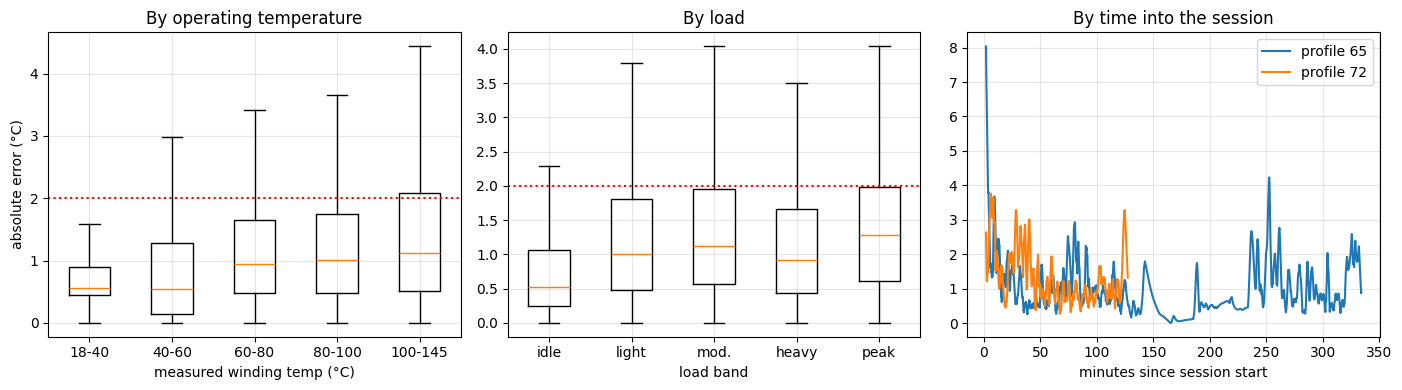

median error by temperature band: [0.57, 0.54, 0.94, 1.0, 1.12]
median error, first 10 min vs after: 2.51 °C  vs  0.73 °C


In [23]:
pb_t = preds[best]
err  = np.abs(yte.values - pb_t)
i_s_te = np.sqrt(df.loc[te,'i_d']**2 + df.loc[te,'i_q']**2).to_numpy()
pid_te = df.loc[te,'profile_id'].to_numpy()

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

tb = [(18,40),(40,60),(60,80),(80,100),(100,145)]
ax[0].boxplot([err[(yte.values>=a)&(yte.values<b)] for a,b in tb], showfliers=False)
ax[0].set_xticklabels([f"{a}-{b}" for a,b in tb]); ax[0].axhline(2, color='r', ls=':')
ax[0].set_xlabel("measured winding temp (°C)"); ax[0].set_ylabel("absolute error (°C)")
ax[0].set_title("By operating temperature")

lb = [(0,5),(5,75),(75,150),(150,250),(250,400)]
ax[1].boxplot([err[(i_s_te>=a)&(i_s_te<b)] for a,b in lb], showfliers=False)
ax[1].set_xticklabels(["idle","light","mod.","heavy","peak"]); ax[1].axhline(2, color='r', ls=':')
ax[1].set_xlabel("load band"); ax[1].set_title("By load")

for q in TEST_P:
    m = pid_te == q; e = err[m]; k = 240
    ax[2].plot(np.arange(len(e))[k-1:]/FS/60, np.convolve(e, np.ones(k)/k, 'valid'), label=f"profile {q}")
ax[2].legend(); ax[2].set_xlabel("minutes since session start")
ax[2].set_title("By time into the session")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"median error by temperature band: "
      f"{[round(float(np.median(err[(yte.values>=a)&(yte.values<b)])),2) for a,b in tb]}")
print(f"median error, first 10 min vs after: ", end="")
first10 = np.concatenate([err[pid_te==q][:1200] for q in TEST_P])
rest    = np.concatenate([err[pid_te==q][1200:] for q in TEST_P])
print(f"{np.median(first10):.2f} °C  vs  {np.median(rest):.2f} °C")

Median error holds near 1 °C across **every** temperature band and **every** load band — accuracy does
not decay when the machine is hot or working hard, which is the property that actually matters, since
the hot regime is the only one in which a thermal limit is ever consulted.

The real structure is in the third panel. **The largest errors sit in the first minutes of a session**,
while the 1800 s and 3600 s EWMAs are still converging from their zero initial state. That warm-up cost
is intrinsic to a recursive feature set, and it is the single most addressable weakness in the model.

## 10. Validating the approach

Two studies that test whether the result is real.

### 10.1 Ablation — where does the accuracy come from?

In [24]:
PHYS = BASE + ["i_s","u_s","S_el","i_s_sq","P_mech","P_loss"]
abl  = {}
for label, cols in [("raw inputs only", BASE),
                    ("+ physical derivations", PHYS),
                    ("+ EWMA (full)", FEATS)]:
    m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=96,
                          min_child_samples=60, random_state=RNG, n_jobs=-1, verbose=-1)
    m.fit(Xtr[cols], ytr)
    abl[label] = scores(yte.values, m.predict(Xte[cols]))
    print(f"{label:<26} RMSE {abl[label]['RMSE']:6.3f}   R2 {abl[label]['R2']:7.4f}")

raw inputs only            RMSE 14.390   R2  0.6942


+ physical derivations     RMSE 14.581   R2  0.6860


+ EWMA (full)              RMSE  2.432   R2  0.9913


Instantaneous physical derivations alone buy essentially **nothing** (R² 0.694 → 0.686 — inside noise).
Adding the EWMAs takes it to 0.991. The gain is not from "more features"; it is specifically from
giving the model *thermal history*.

### 10.2 Leakage study — what a random split would have told us

In [25]:
rs   = np.random.RandomState(RNG)
mask = rs.rand(len(df)) < 0.80
gl = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=96,
                       min_child_samples=60, random_state=RNG, n_jobs=-1, verbose=-1)
gl.fit(df.loc[mask, FEATS], df.loc[mask, TARGET])
leak = scores(df.loc[~mask, TARGET].values, gl.predict(df.loc[~mask, FEATS]))

print(f"random split (leaky)    R2 = {leak['R2']:.4f}   RMSE = {leak['RMSE']:.3f} °C")
print(f"profile-wise (honest)   R2 = {results['LightGBM']['R2']:.4f}   RMSE = {results['LightGBM']['RMSE']:.3f} °C")
print(f"\nRMSE understated by {results['LightGBM']['RMSE']/leak['RMSE']:.1f}x under random splitting.")

random split (leaky)    R2 = 0.9995   RMSE = 0.655 °C
profile-wise (honest)   R2 = 0.9908   RMSE = 2.501 °C

RMSE understated by 3.8x under random splitting.


A random split reports R² = 0.9995 and RMSE = 0.66 °C. The same model, evaluated honestly, achieves
2.50 °C — **3.8× worse**. A project that reported the first number would be reporting the
model's ability to memorise its own training data.

### 10.3 What the model relies on

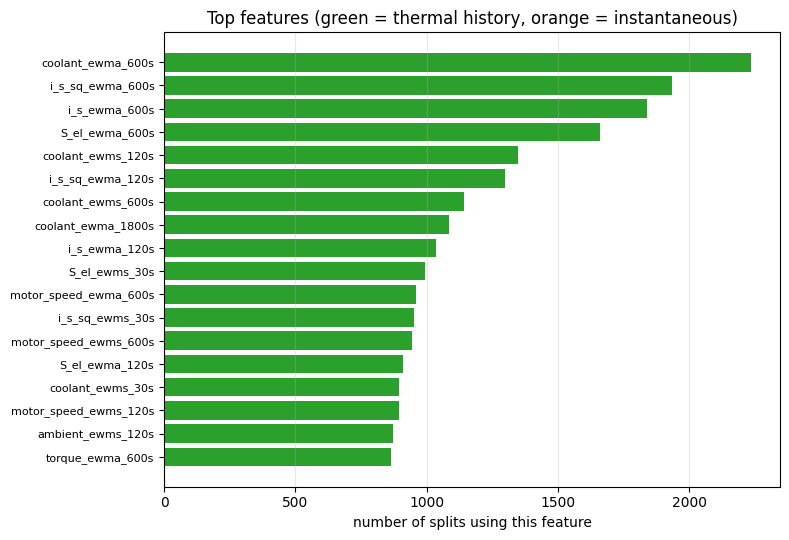

18 of the top 18 features are EWMA-derived.


In [26]:
imp = pd.Series(gbm.feature_importances_, index=FEATS).sort_values(ascending=False).head(18)
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["tab:green" if "ewm" in n else "tab:orange" for n in imp.index[::-1]]
ax.barh(range(len(imp)), imp.values[::-1], color=colors)
ax.set_yticks(range(len(imp))); ax.set_yticklabels(imp.index[::-1], fontsize=8)
ax.set_xlabel("number of splits using this feature")
ax.set_title("Top features (green = thermal history, orange = instantaneous)")
ax.grid(alpha=.3, axis="x"); plt.tight_layout(); plt.show()

print(f"{sum('ewm' in n for n in imp.index)} of the top 18 features are EWMA-derived.")

Every one of the top features is a thermal-history feature, and the ones that dominate are the
600 s EWMAs of coolant temperature and of $i_s^2$ — precisely the copper-loss term and the heat-sink
boundary condition that a lumped thermal model would name. **The model learned the physics we designed
the features around**, which is the strongest available evidence that the result is not an artefact.

## 11. Deployment considerations

The point of a virtual sensor is that it runs on the drive, not in a notebook. Some observations
relevant to that:

- **Inference cost.** The selected MLP is two hidden layers of 128 units over ~104 inputs —
  roughly 30k multiply-accumulates per inference. At the 2 Hz rate the thermal model needs, that is
  negligible for any modern motor-control MCU, and trivially small for an FPGA implementation.
- **The EWMA state is nearly free.** Each EWMA is one multiply-add and one register:
  $y_k = \alpha x_k + (1-\alpha) y_{k-1}$. The 90 EWMA features cost 90 registers and 90 MACs per
  sample — this is a hardware-friendly feature extractor, which is unusual and is part of why this
  formulation is attractive for deployment.
- **Fixed-point feasibility.** Temperatures span 18–141 °C and need ~0.1 °C resolution, so 16-bit
  fixed point is sufficient at the output. The EWMA accumulators need more headroom because of the
  long time constants — Q16.16 accumulators would be a safe starting point.
- **Failure mode.** The worst-case error of the selected model is 11.3 °C, so a deployed thermal limit would need a
  corresponding safety margin below the insulation rating; the model derates the motor less than a
  fixed conservative derating would, but it does not remove the need for a margin.

## 12. Limitations

Stated plainly, because a project that claims no weaknesses has not been examined properly.

1. **Worst-case error is ~11 °C.** A deployed thermal limit still needs a safety margin below the
   insulation rating. The model shrinks that margin relative to a fixed conservative derating; it does
   not remove it.

2. **One machine, one test bench.** Nothing here proves the relationship transfers across motor
   geometries. A different design would need retraining, or transfer learning from limited data on the
   new machine.

3. **Warm-up.** The first minutes of any session are predicted from partially-converged filter states —
   quantified in §9.2, and the largest single source of remaining error.

4. **Tuning improved the average but not the tail.** Worst-case error moved from 9.84 °C to 11.32 °C,
   because the search objective was RMSE and nothing constrained the maximum.

5. **Five training sessions are shorter than the longest EWMA span.** Profiles 47, 46, 52, 64 and 51
   run 18–52 minutes while the 3600 s filter needs a full hour to converge, so ~1.5 % of training rows
   carry a partially-formed feature. None of these are in the validation or test set, so the reported
   results are unaffected — but strictly, not every feature means precisely the same thing in every
   training row.

6. **The CV-to-test gap is large** (≈3 °C vs ≈1.5 °C) because grouped folds train on far fewer
   sessions. The CV number ranks candidates; it does not estimate deployed accuracy.

7. **Session identity is required at inference.** The model is not a pure function of an instantaneous
   sample — it needs correctly segmented, chronologically ordered history, because the features are
   averages over that history.

8. **No uncertainty estimate.** A protection function would rather have a defensible upper bound than a
   point estimate, and none of these models provides one.

### Improvements, in the order worth attempting

| Improvement | What it would fix |
|---|---|
| Seed the EWMA state from the first sample instead of zero | the warm-up error in §9.2 — cheapest win here |
| Physics-informed loss enforcing the thermal ODE | worst-case error specifically, by constraining trajectories to physically realisable ones |
| Quantile regression or conformal prediction | gives the upper bound a protection limit actually wants |
| Sequence model (temporal CNN / LSTM) | learns the time constants instead of fixing five EWMA spans |
| Multi-output prediction of all four temperatures | exploits shared thermal structure between winding, tooth, yoke and magnet |
| Fixed-point quantisation + RTL feature extractor | closes the loop to hardware deployment |

## 13. Conclusions

1. Stator winding temperature can be estimated from drive-measurable signals alone to **RMSE ≈ 1.54 °C,
   R² ≈ 0.9965**, on motor sessions never seen during training, with **84.2 % of samples within
   ±2 °C** and a worst case of **11.32 °C**.
2. **Feature engineering, not model selection, produced the result.** The same linear regression goes
   from R² 0.53 to 0.99 when the inputs encode thermal history. The ablation confirms the gain comes
   specifically from the EWMA terms.
3. **Evaluation protocol changes the reported result by 4×.** Profile-wise splitting is mandatory on
   time-series data of this kind; random splitting produces a number that describes nothing.
4. **A smooth model generalises better than tree ensembles here**, because held-out sessions require
   extrapolation beyond the training envelope.
5. **Tuning helped the average and not the tail.** RMSE and MAE improved by 8 % and 13 %; worst-case
   error got slightly worse, because the search optimised RMSE. Reported, not hidden.
6. **The model learned the intended physics.** Its most-used features are the coolant boundary
   condition and the copper-loss term — the two terms the thermal ODE in §5.2 names as dominant.
7. The resulting estimator is cheap enough to run on the motor controller itself, which is what makes
   it a replacement for a thermocouple rather than an offline analysis.

(Improvements are set out in §12 above, ordered by what they would actually fix.)